# Análise Exploratória de Dados — CERT.br

**Disciplina:** Segurança de Sistemas de Computação  
**Curso:** Engenharia da Computação — IFMT Campus Cuiabá  
**Período:** 2026/1

---

Este notebook conduz uma análise exploratória de dados (AED) sobre incidentes de segurança notificados ao CERT.br, com foco na **série mensal por categoria de incidente** (2016–2026).

## Estrutura da apresentação

1. **Escolha da base** — por que CERT.br e por que esse dataset
2. **Análise das variáveis** — estrutura, tipos, distribuição
3. **Perguntas de pesquisa** — o que queremos descobrir
4. **Insights com gráficos** — análises e visualizações
5. **Perspectivas complementares** — outros datasets do CERT.br
6. **Caminho para o artigo** — próximos passos

## Setup — bibliotecas e configurações

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Configurações visuais
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

# Caminho dos dados (relativo à raiz do projeto)
DADOS = Path("dados_certbr")
assert DADOS.exists(), f"Diretório {DADOS} não encontrado. Coloque o notebook na raiz do projeto."

# Paleta consistente para as 6 categorias
PALETA_CAT = {
    "Scan":     "#1f77b4",
    "DoS":      "#d62728",
    "Fraude":   "#ff7f0e",
    "Web":      "#2ca02c",
    "Outros":   "#7f7f7f",
    "Invasao":  "#9467bd",
}

print("Setup concluído.")
print(f"Pasta de dados: {DADOS.resolve()}")

Setup concluído.
Pasta de dados: /home/anabe/Documentos/IFMT/7º SEMESTRE/SEGURANÇA DE SISTEMAS DA COMPUTAÇÃO/projeto-certbr/dados_certbr


---

## Parte 1 — Escolha da base

### Por que o CERT.br?

O **CERT.br** (Centro de Estudos, Resposta e Tratamento de Incidentes de Segurança no Brasil) é mantido pelo NIC.br/CGI.br e é a referência oficial de dados de segurança da internet brasileira. As estatísticas estão disponíveis publicamente em `stats.cert.br` sob licença Creative Commons CC BY-NC-ND 4.0.

**Justificativas para a escolha:**

- Fonte oficial e reconhecida pela comunidade acadêmica brasileira de segurança
- Série histórica de mais de 25 anos (1999–2026)
- Cobertura nacional — incidentes em redes brasileiras
- Cobre todos os tópicos do plano de ensino: DoS, malware, phishing, autenticação, varreduras, intrusão
- Licença permite uso em pesquisa acadêmica

### Por que o dataset `tipos_incidente_mensal.csv`?

Dentre os 9 datasets disponíveis no CERT.br, escolhemos `tipos_incidente_mensal.csv` como protagonista porque:

- É o mais **rico** (4 variáveis: ano, mês, categoria, total)
- Permite **múltiplos ângulos de análise**: temporal, sazonal, composicional
- Cobre **11 anos consistentes** (2016–2026)
- Tem **6 categorias** de classificação que mapeiam diretamente nos tópicos da disciplina

In [2]:
# Carrega o dataset principal
df = pd.read_csv(DADOS / "tipos_incidente_mensal.csv", parse_dates=["data"])
print(f"Dataset carregado: {df.shape[0]} linhas × {df.shape[1]} colunas")
df.head(10)

Dataset carregado: 868 linhas × 6 colunas


,ano,mes,data,categoria,total,percentual
0,2016,1,2016-01-01,total_geral,49761,NaN
1,2016,1,2016-01-01,DoS,942,1.89
2,2016,1,2016-01-01,Fraude,11820,23.75
3,2016,1,2016-01-01,Invasao,272,0.55
4,2016,1,2016-01-01,Outros,1502,3.02
5,2016,1,2016-01-01,Scan,32959,66.23
6,2016,1,2016-01-01,Web,2266,4.55
7,2016,2,2016-02-01,total_geral,52843,NaN
8,2016,2,2016-02-01,DoS,137,0.26
9,2016,2,2016-02-01,Fraude,8761,16.58


---

## Parte 2 — Análise das variáveis

Antes de qualquer análise visual, precisamos entender a estrutura dos dados:

1. Tipos das variáveis (numéricas, categóricas, temporais)
2. Cobertura temporal
3. Valores faltantes
4. Distribuição estatística

Conforme o material da disciplina (Hadley Wickham — R for Data Science), as primeiras perguntas da EDA são sobre **variação dentro de cada variável**.

### 2.1  Estrutura geral (tipos e nulos)

In [3]:
print("=== Tipos e contagem de nulos ===\n")
df.info()
print("\n=== Valores faltantes por coluna ===")
print(df.isnull().sum())

=== Tipos e contagem de nulos ===

<class 'pandas.DataFrame'>
RangeIndex: 868 entries, 0 to 867
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   ano         868 non-null    int64         
 1   mes         868 non-null    int64         
 2   data        868 non-null    datetime64[us]
 3   categoria   868 non-null    str           
 4   total       868 non-null    int64         
 5   percentual  744 non-null    float64       
dtypes: datetime64[us](1), float64(1), int64(3), str(1)
memory usage: 40.8 KB

=== Valores faltantes por coluna ===
ano             0
mes             0
data            0
categoria       0
total           0
percentual    124
dtype: int64


**Observação importante:** a coluna `percentual` tem valores nulos onde `categoria == 'total_geral'`. Isso é esperado: o total geral do mês não tem percentual sobre si mesmo. Vamos lidar com isso separando o total das categorias.

In [4]:
# Separa total geral das categorias específicas
df_total = df[df["categoria"] == "total_geral"].copy()
df_cat = df[df["categoria"] != "total_geral"].copy()

print(f"Total geral (1 linha por mês):  {len(df_total)} registros")
print(f"Por categoria (6 cats/mês):     {len(df_cat)} registros")
print(f"\nCategorias presentes: {sorted(df_cat['categoria'].unique())}")

Total geral (1 linha por mês):  124 registros
Por categoria (6 cats/mês):     744 registros

Categorias presentes: ['DoS', 'Fraude', 'Invasao', 'Outros', 'Scan', 'Web']


### 2.2  Cobertura temporal

In [5]:
print(f"Período:  {df['data'].min()} → {df['data'].max()}")
print(f"Anos:     {sorted(df['ano'].unique())}")
print(f"\nMeses por ano:")
print(df.groupby("ano")["mes"].nunique())

Período:  2016-01-01 00:00:00 → 2026-04-01 00:00:00
Anos:     [np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025), np.int64(2026)]

Meses por ano:
ano
2016    12
2017    12
2018    12
2019    12
2020    12
2021    12
2022    12
2023    12
2024    12
2025    12
2026     4
Name: mes, dtype: int64


**Observação:** o ano de 2026 tem menos meses por ser parcial (período em andamento). Vamos manter o dado, mas considerar esse fato nas análises temporais.

### 2.3  Estatísticas descritivas

In [6]:
print("=== Total mensal (variável principal) ===")
df_total["total"].describe().round(0)

=== Total mensal (variável principal) ===


count       124.0
mean      48907.0
std       26704.0
min       25623.0
25%       38514.0
50%       44805.0
75%       52738.0
max      252645.0
Name: total, dtype: float64

In [7]:
print("=== Estatísticas por categoria ===")
df_cat.groupby("categoria")["total"].describe().round(0)

=== Estatísticas por categoria ===


,count,mean,std,min,25%,50%,75%,max
categoria,,,,,,,,
DoS,124.0,8907.0,25627.0,8.0,912.0,4278.0,7512.0,207780.0
Fraude,124.0,3404.0,2312.0,1389.0,2118.0,2610.0,3638.0,14431.0
Invasao,124.0,145.0,149.0,1.0,67.0,106.0,171.0,1102.0
Outros,124.0,1016.0,2719.0,30.0,155.0,322.0,824.0,19065.0
Scan,124.0,33293.0,9021.0,16809.0,27312.0,33005.0,37734.0,60890.0
Web,124.0,2141.0,2266.0,295.0,740.0,1253.0,2508.0,12169.0


### 2.4  Distribuição do total mensal

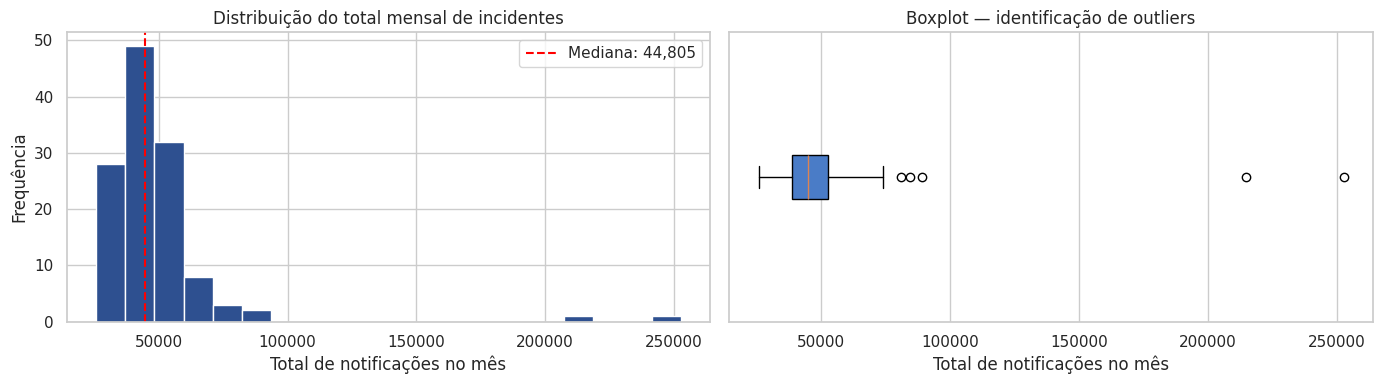

Limite superior (Q3 + 1.5*IQR): 74,074

Outliers identificados (5 meses):
      data  total
2017-07-01 252645
2019-06-01 214632
2016-03-01  88934
2018-08-01  84319
2019-03-01  80933


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Histograma
axes[0].hist(df_total["total"], bins=20, color="#2E5090", edgecolor="white")
axes[0].set_xlabel("Total de notificações no mês")
axes[0].set_ylabel("Frequência")
axes[0].set_title("Distribuição do total mensal de incidentes")
axes[0].axvline(df_total["total"].median(), color="red", linestyle="--",
                label=f"Mediana: {df_total['total'].median():,.0f}")
axes[0].legend()

# Boxplot
axes[1].boxplot(df_total["total"], vert=False, patch_artist=True,
                boxprops=dict(facecolor="#4A7CC7"))
axes[1].set_xlabel("Total de notificações no mês")
axes[1].set_title("Boxplot — identificação de outliers")
axes[1].set_yticks([])

plt.tight_layout()
plt.show()

# Outliers
q1, q3 = df_total["total"].quantile([0.25, 0.75])
iqr = q3 - q1
limite_sup = q3 + 1.5 * iqr
outliers = df_total[df_total["total"] > limite_sup].sort_values("total", ascending=False)
print(f"Limite superior (Q3 + 1.5*IQR): {limite_sup:,.0f}")
print(f"\nOutliers identificados ({len(outliers)} meses):")
print(outliers[["data", "total"]].to_string(index=False))

---

## Parte 3 — Perguntas de pesquisa

A partir do entendimento da estrutura dos dados, formulamos as seguintes perguntas que guiarão a análise:

**P1.** Como evoluiu o volume total de notificações ao longo dos anos? Há tendência clara de crescimento ou estabilização?

**P2.** Existe **sazonalidade** nas notificações? Alguns meses do ano concentram mais incidentes que outros?

**P3.** Como mudou a **composição** dos ataques ao longo do tempo? A proporção entre Scan, DoS, Fraude, Web, Invasão e Outros se manteve estável?

**P4.** Quais categorias **cresceram** e quais **decresceram** no período?

**P5.** Há **eventos atípicos** (meses com comportamento muito fora do padrão) que mereçam investigação especial?

---

## Parte 4 — Insights com gráficos

Cinco visualizações respondem às perguntas formuladas acima.

### Gráfico 1 — Evolução temporal por categoria (responde P1 e P4)

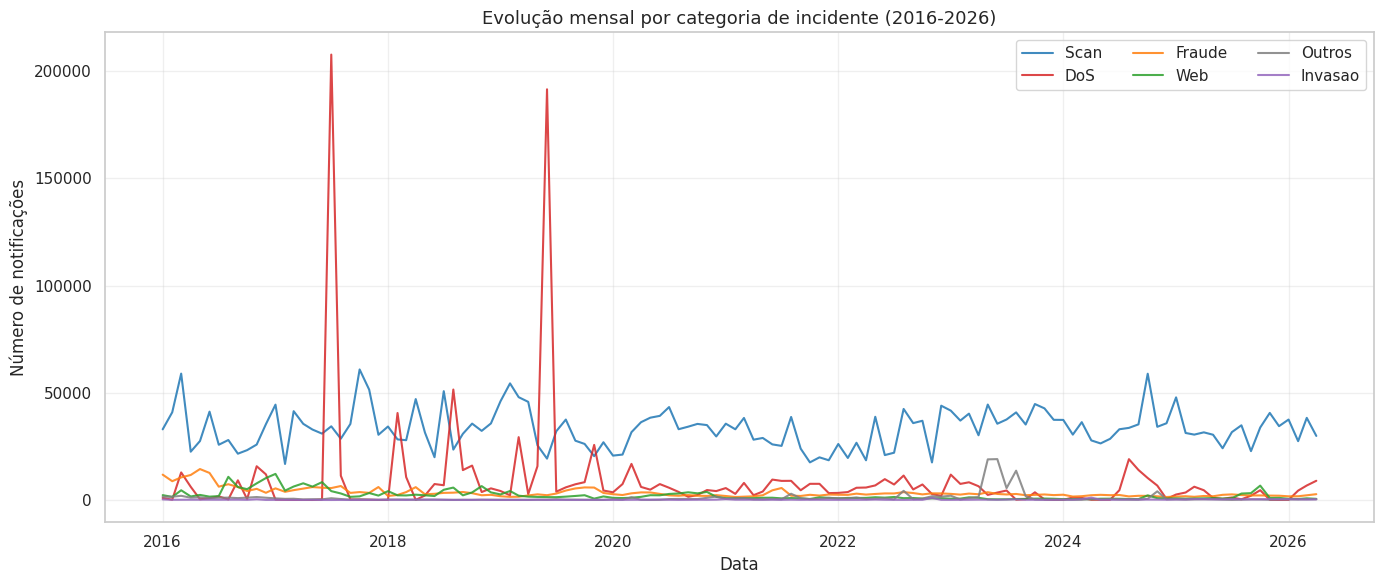

In [9]:
fig, ax = plt.subplots(figsize=(14, 6))

for cat in ["Scan", "DoS", "Fraude", "Web", "Outros", "Invasao"]:
    sub = df_cat[df_cat["categoria"] == cat].sort_values("data")
    ax.plot(sub["data"], sub["total"], label=cat,
            color=PALETA_CAT[cat], linewidth=1.5, alpha=0.85)

ax.set_title("Evolução mensal por categoria de incidente (2016-2026)", fontsize=13)
ax.set_xlabel("Data")
ax.set_ylabel("Número de notificações")
ax.legend(loc="upper right", ncol=3)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Insight a explorar:**  
_(Observe quais categorias dominam, picos isolados, tendências de longo prazo. Anote aqui suas observações para a apresentação.)_

### Gráfico 2 — Heatmap ano × mês do total geral (responde P2)

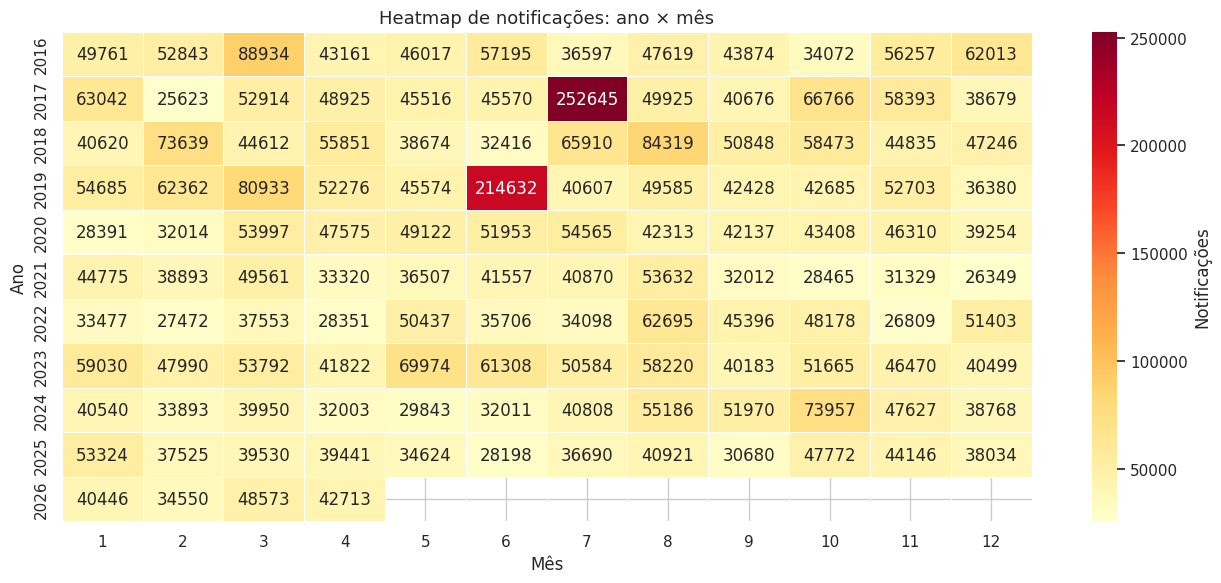


Média de notificações por mês (todos os anos):
mes
1     46190.0
2     42437.0
3     53668.0
4     42313.0
5     44629.0
6     60055.0
7     65337.0
8     54442.0
9     42020.0
10    49544.0
11    45488.0
12    41862.0
Name: total, dtype: float64


In [10]:
# Pivot: ano nas linhas, mês nas colunas
heatmap = df_total.pivot_table(
    index="ano", columns="mes", values="total", aggfunc="sum"
)

fig, ax = plt.subplots(figsize=(13, 6))
sns.heatmap(heatmap, annot=True, fmt=".0f", cmap="YlOrRd",
            cbar_kws={"label": "Notificações"}, ax=ax,
            linewidths=0.5, linecolor="white")
ax.set_title("Heatmap de notificações: ano × mês", fontsize=13)
ax.set_xlabel("Mês")
ax.set_ylabel("Ano")
plt.tight_layout()
plt.show()

# Média por mês (todos os anos juntos)
print("\nMédia de notificações por mês (todos os anos):")
print(df_total.groupby("mes")["total"].mean().round(0))

**Insight a explorar:**  
_(Quais meses estão mais quentes no heatmap? O padrão é consistente entre anos ou varia? Há linhas/colunas inteiras destoantes?)_

### Gráfico 3 — Composição relativa (100% stacked area) (responde P3)

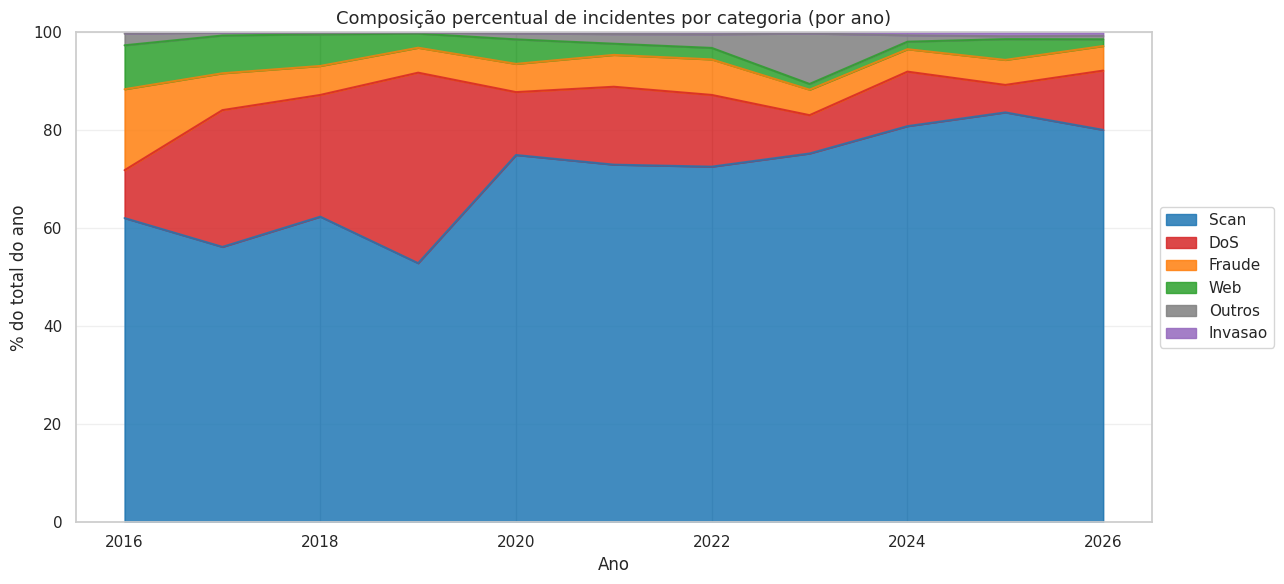


Percentual de cada categoria por ano:
categoria  Scan   DoS  Fraude  Web  Outros  Invasao
ano                                                
2016       62.1   9.8    16.5  9.0     2.4      0.3
2017       56.2  27.9     7.5  7.7     0.6      0.1
2018       62.4  24.9     5.9  6.5     0.2      0.2
2019       52.9  38.9     5.1  2.9     0.2      0.1
2020       75.0  12.8     5.8  5.0     1.2      0.2
2021       73.0  15.9     6.5  2.3     2.0      0.4
2022       72.6  14.6     7.2  2.3     2.8      0.4
2023       75.3   7.8     5.2  1.2    10.3      0.2
2024       80.8  11.1     4.6  1.5     1.3      0.6
2025       83.7   5.6     5.1  4.2     0.6      0.8
2026       80.1  12.1     5.0  1.4     0.7      0.7


In [11]:
# Agrega por ano e categoria, calcula percentual sobre o total anual
anual_cat = df_cat.groupby(["ano", "categoria"])["total"].sum().reset_index()
totais_anuais = anual_cat.groupby("ano")["total"].sum().to_dict()
anual_cat["pct"] = anual_cat.apply(
    lambda r: 100 * r["total"] / totais_anuais[r["ano"]], axis=1
)

pivot_pct = anual_cat.pivot(index="ano", columns="categoria", values="pct")
ordem = ["Scan", "DoS", "Fraude", "Web", "Outros", "Invasao"]
pivot_pct = pivot_pct[ordem]

fig, ax = plt.subplots(figsize=(13, 6))
pivot_pct.plot(kind="area", stacked=True, ax=ax,
               color=[PALETA_CAT[c] for c in ordem], alpha=0.85)
ax.set_title("Composição percentual de incidentes por categoria (por ano)", fontsize=13)
ax.set_xlabel("Ano")
ax.set_ylabel("% do total do ano")
ax.set_ylim(0, 100)
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))
ax.grid(True, alpha=0.3, axis="y")
plt.tight_layout()
plt.show()

print("\nPercentual de cada categoria por ano:")
print(pivot_pct.round(1))

**Insight a explorar:**  
_(Olhe se a fatia de cada categoria aumentou ou diminuiu ao longo dos anos. Há mudanças de "dominância"?)_

### Gráfico 4 — Variabilidade entre meses, por categoria (responde P4)

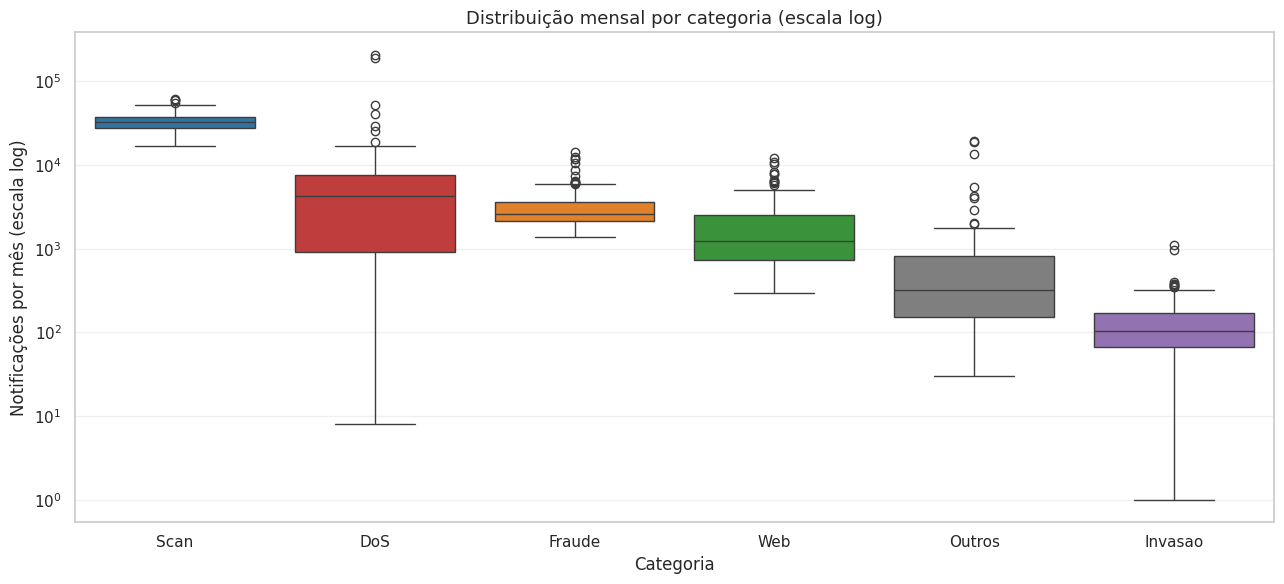

In [12]:
fig, ax = plt.subplots(figsize=(13, 6))

ordem_box = (df_cat.groupby("categoria")["total"].median()
             .sort_values(ascending=False).index.tolist())

sns.boxplot(data=df_cat, x="categoria", y="total", order=ordem_box,
            hue="categoria", palette=PALETA_CAT, legend=False, ax=ax)
ax.set_yscale("log")
ax.set_title("Distribuição mensal por categoria (escala log)", fontsize=13)
ax.set_xlabel("Categoria")
ax.set_ylabel("Notificações por mês (escala log)")
ax.grid(True, alpha=0.3, axis="y")
plt.tight_layout()
plt.show()

**Por que escala logarítmica?** As categorias têm magnitudes muito diferentes (Scan em centenas de milhares, Invasão em centenas). A escala log permite ver a distribuição de todas no mesmo gráfico.

**Insight a explorar:**  
_(Quais categorias têm maior variabilidade? Quais têm outliers? A mediana de DoS, por exemplo, está acima ou abaixo de Fraude?)_

### Gráfico 5 — Zoom no outlier de julho/2017 (responde P5)

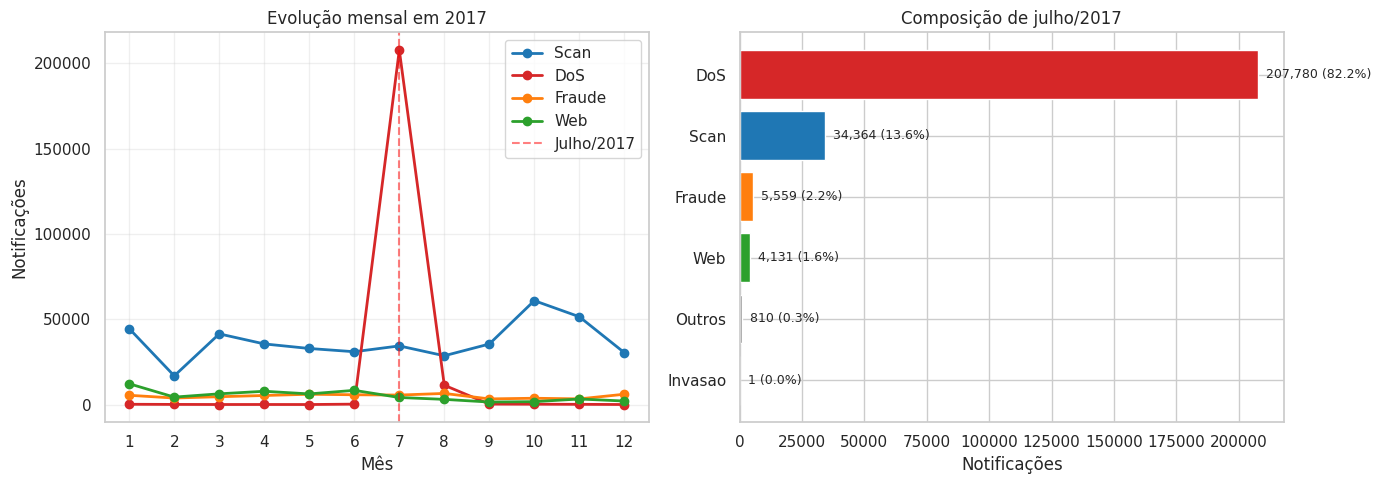


Detalhe de julho/2017:
categoria  total  percentual
      DoS 207780       82.24
     Scan  34364       13.60
   Fraude   5559        2.20
      Web   4131        1.64
   Outros    810        0.32
  Invasao      1        0.00


In [13]:
# Filtra apenas 2017 e separa o pico de julho
df_2017 = df_cat[df_cat["ano"] == 2017].copy()
jul_2017 = df_2017[df_2017["mes"] == 7].sort_values("total", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Esquerda — evolução mensal de 2017 por categoria
for cat in ["Scan", "DoS", "Fraude", "Web"]:
    sub = df_2017[df_2017["categoria"] == cat].sort_values("mes")
    axes[0].plot(sub["mes"], sub["total"], marker="o",
                  label=cat, color=PALETA_CAT[cat], linewidth=2)
axes[0].set_xticks(range(1, 13))
axes[0].set_title("Evolução mensal em 2017", fontsize=12)
axes[0].set_xlabel("Mês")
axes[0].set_ylabel("Notificações")
axes[0].axvline(7, color="red", linestyle="--", alpha=0.5, label="Julho/2017")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Direita — composição do mês de julho/2017
axes[1].barh(jul_2017["categoria"], jul_2017["total"],
             color=[PALETA_CAT[c] for c in jul_2017["categoria"]])
axes[1].set_title("Composição de julho/2017", fontsize=12)
axes[1].set_xlabel("Notificações")
for i, (cat, val, pct) in enumerate(zip(
    jul_2017["categoria"], jul_2017["total"], jul_2017["percentual"]
)):
    axes[1].text(val, i, f"  {val:,.0f} ({pct:.1f}%)", va="center", fontsize=9)
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

print("\nDetalhe de julho/2017:")
print(jul_2017[["categoria", "total", "percentual"]].to_string(index=False))

**Insight a explorar:**  
_Em julho/2017, a categoria DoS representou 82% das notificações do mês — totalmente fora do padrão (nos outros meses de 2017, DoS ficou abaixo de 1% na maior parte do tempo). Vale investigar o que causou esse evento: foi um ataque coordenado específico? Uma campanha contra redes brasileiras?_

_Para a apresentação, vale buscar reportagens da época ou o relatório anual do CERT.br de 2017 para contextualizar._

---

## Parte 5 — Perspectivas complementares

O foco da análise foi no detalhamento mensal por categoria (2016-2026), mas o CERT.br oferece outros 8 datasets que ampliam a perspectiva. Aqui dois exemplos rápidos:

### 5.1  Série histórica longa (1999-2026)

O CSV `incidentes_anual.csv` cobre **28 anos** de dados, três vezes mais que o nosso recorte mensal.

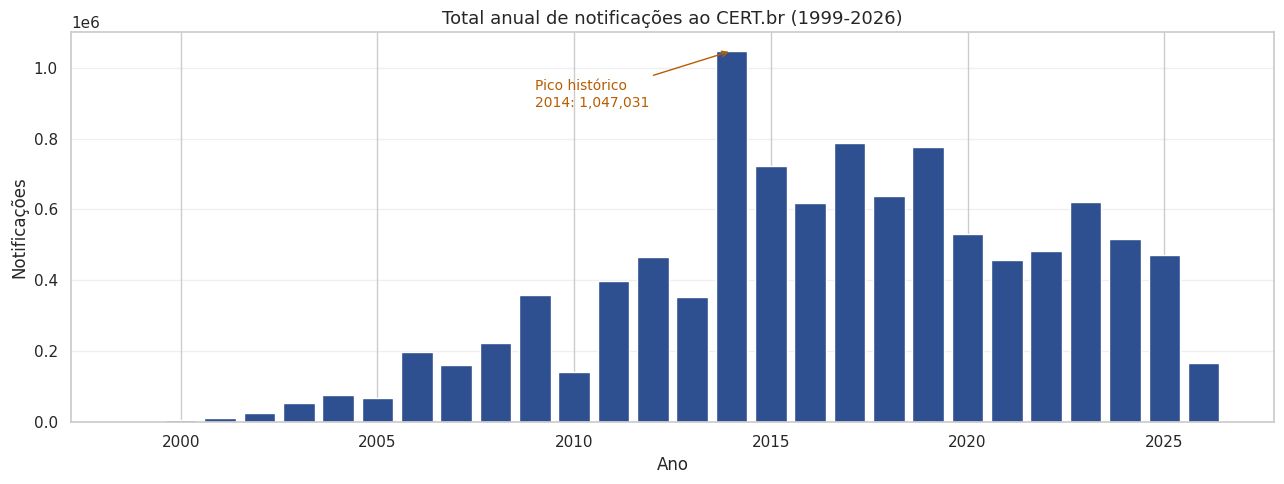


Maior ano: 2014 (1,047,031 notificações)
Total acumulado em todo histórico: 10,378,689


In [14]:
df_hist = pd.read_csv(DADOS / "incidentes_anual.csv")

fig, ax = plt.subplots(figsize=(13, 5))
ax.bar(df_hist["ano"], df_hist["valor"], color="#2E5090", edgecolor="white")
ax.set_title("Total anual de notificações ao CERT.br (1999-2026)", fontsize=13)
ax.set_xlabel("Ano")
ax.set_ylabel("Notificações")
ax.grid(True, alpha=0.3, axis="y")

# Destacar o pico de 2014 (Copa do Mundo)
pico = df_hist.loc[df_hist["valor"].idxmax()]
ax.annotate(
    f"Pico histórico\n{pico['ano']}: {pico['valor']:,.0f}",
    xy=(pico["ano"], pico["valor"]),
    xytext=(pico["ano"]-5, pico["valor"]*0.85),
    fontsize=10, color="#B85C00",
    arrowprops=dict(arrowstyle="->", color="#B85C00"),
)
plt.tight_layout()
plt.show()

print(f"\nMaior ano: {pico['ano']} ({pico['valor']:,.0f} notificações)")
print(f"Total acumulado em todo histórico: {df_hist['valor'].sum():,.0f}")

**Observação para apresentação:** o pico de 2014 coincide com o ano da Copa do Mundo no Brasil — vale investigar se houve relação com ataques motivados pelo evento (defacements, DDoS contra sites governamentais, etc.).

### 5.2  Origem geográfica dos ataques

O CSV `top_cc.csv` revela quais países são as principais origens das varreduras e tentativas de ataque contra redes brasileiras.

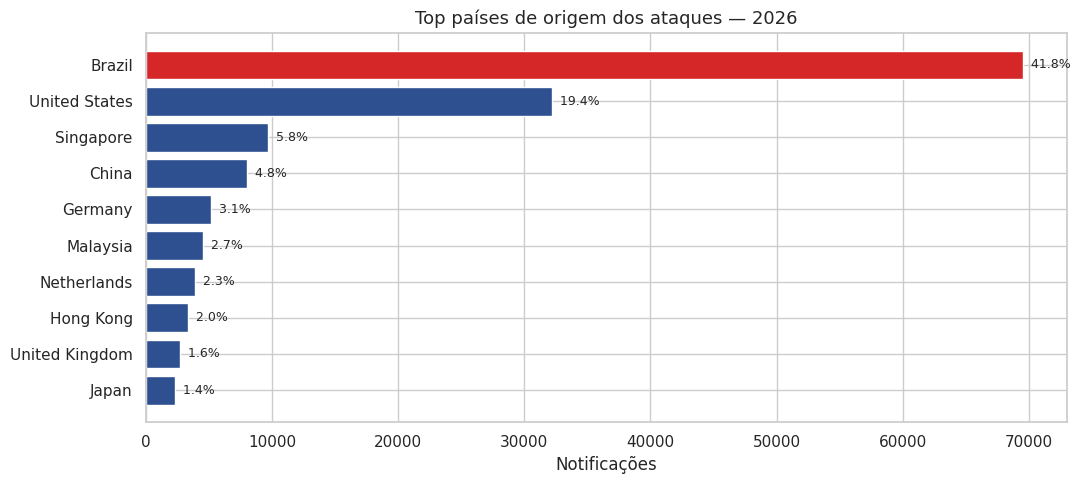


Observação: o Brasil é destacadamente a maior origem de ataques
contra redes brasileiras (~52% em 2017). Isso é coerente com o
fato de muitos ataques partirem de máquinas comprometidas no próprio país.


In [15]:
df_cc = pd.read_csv(DADOS / "top_cc.csv")
anos_cc = sorted(df_cc["ano"].unique())
ano_ref = anos_cc[-1] if anos_cc else 2017  # usa o ano mais recente disponível
df_cc_ref = df_cc[df_cc["ano"] == ano_ref].sort_values("total", ascending=True)

fig, ax = plt.subplots(figsize=(11, 5))
cores = ["#2E5090" if cc != "BR" else "#D62728"
         for cc in df_cc_ref["cc"]]
ax.barh(df_cc_ref["nome_pais"], df_cc_ref["total"],
        color=cores, edgecolor="white")
ax.set_title(f"Top países de origem dos ataques — {ano_ref}", fontsize=13)
ax.set_xlabel("Notificações")
for i, (_, row) in enumerate(df_cc_ref.iterrows()):
    ax.text(row["total"], i, f"  {row['percentual']:.1f}%",
            va="center", fontsize=9)
plt.tight_layout()
plt.show()

print(f"\nObservação: o Brasil é destacadamente a maior origem de ataques")
print(f"contra redes brasileiras (~52% em 2017). Isso é coerente com o")
print(f"fato de muitos ataques partirem de máquinas comprometidas no próprio país.")

---

## Parte 6 — Caminho para o artigo

Esta AED foi um **primeiro mergulho** no dataset e abre várias possibilidades para o artigo científico final:

### Linhas de aprofundamento possíveis

1. **Investigação do evento de julho/2017** — buscar reportagens da época, relatório anual do CERT.br, e contextualizar tecnicamente o ataque
2. **Decomposição da Fraude** — usar `tipos_fraude_mensal.csv` para mostrar a evolução de Phishing vs Malware
3. **Análise de infraestrutura** — usar `top_portas.csv` para identificar quais serviços são alvos persistentes (SSH, RDP, Telnet)
4. **Análise de origem** — usar `top_asn.csv` para identificar quais sistemas autônomos brasileiros estão mais frequentemente envolvidos como origem
5. **Comparação com eventos macro** — Copa do Mundo (2014), Olimpíadas (2016), Pandemia (2020) — há relação com picos?

### Validações estatísticas a fazer

- Teste de tendência (Mann-Kendall) para confirmar se há crescimento/decréscimo significativo
- Decomposição sazonal (STL) para isolar tendência, sazonalidade e resíduo
- Correlação entre categorias mês a mês — DoS e Scan são correlacionados?

### Limitações do dataset (a citar no artigo)

- Notificações voluntárias: subestimam o total real de ataques
- Dados agregados: sem acesso a registros individuais
- Categorias mudaram metodologicamente entre 1999 e 2020 (uso do histórico antigo exige cuidado)

---

**Fonte dos dados:** CERT.br — `https://stats.cert.br/data/incidentes/`  
**Licença:** Creative Commons CC BY-NC-ND 4.0